In [25]:
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
catalogue = pd.read_csv("../data/raw/CatalogueDiscontinuation.csv")

In [9]:
catalogue.head()

,CatEdition,SpringSummer,ProductKey,WeeksOut,Status,SalePriceIncVAT,ForecastPerWeek,ActualsPerWeek,DiscontinuedTF
0,89,True,8108,-11,RI,43.99,250.545,248.642,False
1,89,True,8108,-10,RI,43.99,255.700,244.333,False
2,89,True,8108,-9,RI,43.99,206.111,252.187,False
3,89,True,8108,-8,RI,43.99,188.625,254.764,False
4,89,True,8108,-7,RI,43.99,169.142,249.000,False


In [10]:
catalogue.shape

(3625659, 9)

In [11]:
catalogue["ProductKey"].nunique()

70227

In [13]:
catalogue.isna().sum()

CatEdition         0
SpringSummer       0
ProductKey         0
WeeksOut           0
Status             0
SalePriceIncVAT    0
ForecastPerWeek    0
ActualsPerWeek     0
DiscontinuedTF     0
dtype: int64

In [14]:
catalogue.duplicated().sum()

np.int64(0)

In [15]:
catalogue["DiscontinuedTF"].value_counts()

DiscontinuedTF
False    2186167
True     1439492
Name: count, dtype: int64

In [16]:
pd.crosstab(catalogue["CatEdition"], catalogue["DiscontinuedTF"]) # crosstab combination of rows frequency

DiscontinuedTF,False,True
CatEdition,,
88,347442,194374
89,361416,192438
90,324776,189678
91,376018,160689
92,367438,158717
93,409077,212199
94,0,331397


In [17]:
catalogue["CatEdition"].nunique()

7

In [18]:
catalogue.groupby("CatEdition")["WeeksOut"].agg(["min", "max"])

,min,max
CatEdition,,
88,-24,-1
89,-24,-1
90,-24,-1
91,-24,-1
92,-24,-1
93,-24,-1
94,-24,-13


In [19]:
catalogue.groupby("CatEdition")["WeeksOut"].nunique()

CatEdition
88    24
89    24
90    24
91    24
92    24
93    24
94    12
Name: WeeksOut, dtype: int64

In [20]:
catalogue[["SalePriceIncVAT", "ForecastPerWeek", "ActualsPerWeek"]].describe()

,SalePriceIncVAT,ForecastPerWeek,ActualsPerWeek
count,3.625659e+06,3.625659e+06,3.625659e+06
mean,7.816104e+01,1.316644e+02,1.090412e+02
std,1.546267e+02,3.917360e+02,2.596290e+02
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.599000e+01,1.514200e+01,1.055500e+01
50%,2.999000e+01,4.660000e+01,3.866600e+01
75%,6.999000e+01,1.270600e+02,1.108330e+02
max,5.000000e+03,1.637575e+05,4.362633e+04


In [21]:
(catalogue["SalePriceIncVAT"] == 0).sum() #why are there 0 sale price?

np.int64(12880)

In [22]:
catalogue[catalogue["SalePriceIncVAT"] == 0].head(10)

,CatEdition,SpringSummer,ProductKey,WeeksOut,Status,SalePriceIncVAT,ForecastPerWeek,ActualsPerWeek,DiscontinuedTF
49427,88,False,7519,-2,RO,0.0,252.000,0.000,True
49428,88,False,7519,-1,RO,0.0,253.000,0.000,True
49429,89,True,7519,-20,RO,0.0,65.050,2.200,True
49430,89,True,7519,-19,RO,0.0,102.157,20.333,True
49431,89,True,7519,-18,RO,0.0,154.944,44.000,True
49432,89,True,7519,-17,RO,0.0,142.411,50.375,True
49433,89,True,7519,-16,RO,0.0,98.812,45.000,True
49434,89,True,7519,-15,RO,0.0,69.533,40.500,True
49435,89,True,7519,-14,RO,0.0,50.285,36.818,True
49436,89,True,7519,-13,RO,0.0,37.153,33.750,True


In [ ]:
catalogue.loc[catalogue["SalePriceIncVAT"] == 0, "ProductKey"].nunique() #locate the number of  products with 0 sale price

402

In [24]:
zero_price_products = catalogue.loc[ catalogue["SalePriceIncVAT"] == 0, "ProductKey"]

catalogue.loc[ catalogue["ProductKey"].isin(zero_price_products)].groupby("ProductKey")["SalePriceIncVAT"].max().gt(0).value_counts() #find highest price of those specific products see if theyre greater than 0

SalePriceIncVAT
False    380
True      22
Name: count, dtype: int64

There are 12,880 0 price observations across 402 products. Of these products, 380 have no recorded price over 0,  22 have both zero and positive prices.

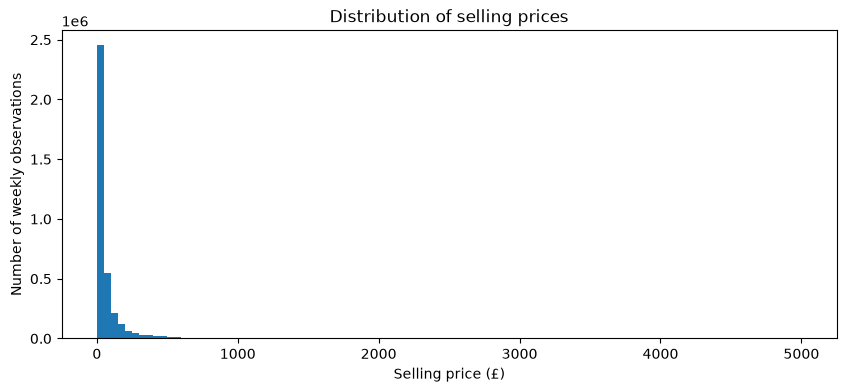

In [26]:

catalogue["SalePriceIncVAT"].plot.hist(bins=100, figsize=(10, 4))
plt.xlabel("Selling price (£)")
plt.ylabel("Number of weekly observations")
plt.title("Distribution of selling prices")
plt.show()

In [27]:
(catalogue["SalePriceIncVAT"] > 1000).sum()

np.int64(15428)

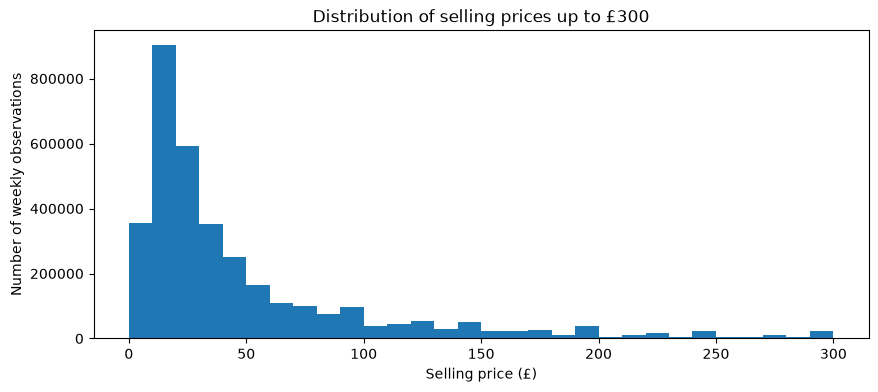

In [28]:
catalogue.loc[catalogue["SalePriceIncVAT"] <= 300, "SalePriceIncVAT"].plot.hist(bins=30, figsize=(10, 4))

plt.xlabel("Selling price (£)")
plt.ylabel("Number of weekly observations")
plt.title("Distribution of selling prices up to £300")
plt.show()

In [29]:
catalogue.groupby("DiscontinuedTF")[["SalePriceIncVAT", "ForecastPerWeek", "ActualsPerWeek"]].median()

,SalePriceIncVAT,ForecastPerWeek,ActualsPerWeek
DiscontinuedTF,,,
False,29.99,66.555,58.250
True,29.99,23.416,17.076


In [30]:
pd.crosstab(
    catalogue["Status"],
    catalogue["DiscontinuedTF"],
    normalize="index"
)

DiscontinuedTF,False,True
Status,,
RI,0.839161,0.160839
RO,0.181859,0.818141


# Product details

In [31]:
products = pd.read_csv("../data/raw/ProductDetails.csv")
products.head()

,ProductKey,Supplier,HierarchyLevel1,HierarchyLevel2,DIorDOM,Seasonal
0,30437,13194,80445,28611,DOM,False
1,68587,13194,80445,28611,DOM,False
2,46645,13194,80445,28611,DOM,False
3,49343,13194,80445,28611,DOM,False
4,64223,13194,80445,28611,DOM,False


In [32]:
print("Dimensions:", products.shape)
print("Missing values:\n", products.isna().sum())
print("Repeated product IDs:", products["ProductKey"].duplicated().sum())

Dimensions: (77372, 6)
Missing values:
 ProductKey         0
Supplier           0
HierarchyLevel1    0
HierarchyLevel2    0
DIorDOM            0
Seasonal           0
dtype: int64
Repeated product IDs: 0


In [33]:
merged = catalogue.merge(
    products,
    on="ProductKey",
    how="left",
    validate="many_to_one"
)

merged.shape

(3625659, 14)

In [36]:
pd.crosstab(merged["Seasonal"],merged["DiscontinuedTF"],normalize="index")

DiscontinuedTF,False,True
Seasonal,,
False,0.599778,0.400222
True,0.650397,0.349603


In [37]:
pd.crosstab(merged["DIorDOM"],merged["DiscontinuedTF"],normalize="index")

DiscontinuedTF,False,True
DIorDOM,,
DI,0.634408,0.365592
DOM,0.586793,0.413207


In [39]:
category = broader_categories[broader_categories > 1].index[0]

products.loc[
    products["HierarchyLevel1"] == category,
    ["HierarchyLevel1", "HierarchyLevel2"]
].drop_duplicates()

,HierarchyLevel1,HierarchyLevel2
42643,124,56920
42644,124,44977


57 specific category codes map to multiple broader categories, opposed to the data dictionary. Both fields keps as supplied during exploration, pending decision during data preparation.

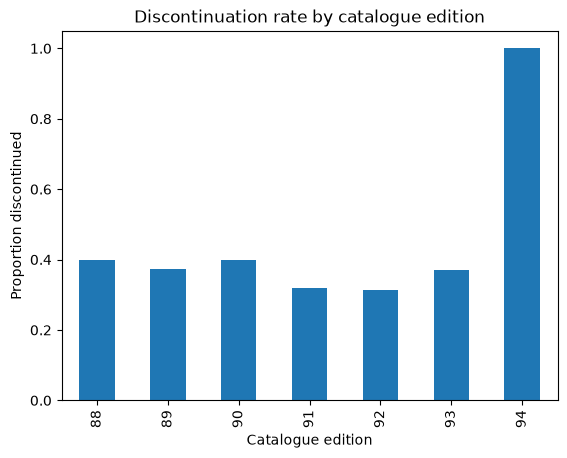

In [40]:
product_editions = catalogue.drop_duplicates(
    subset=["CatEdition", "ProductKey"]
)

edition_rates = product_editions.groupby("CatEdition")[
    "DiscontinuedTF"
].mean()

edition_rates.plot.bar()
plt.xlabel("Catalogue edition")
plt.ylabel("Proportion discontinued")
plt.title("Discontinuation rate by catalogue edition")
plt.show()

Counting each product once per edition, discontinuation rates were something like 31–40% for editions 88–93, 100% for edition 94. Edition 94 also contains only weeks −24 to −13. 94 requires investigation before deciding how to use it in modelling.